# Part 1: Selecting a Small Language Model (SLM) after Running Experiments


In [1]:
# pip install psutil

In [2]:
# ============================================================
# CELL 0: TRAINING PRESETS
# ============================================================
# Choose how long you want to train the model.
#
# quick:     Verify that the model works.
# classroom: Observe learning during class.
# extended:  Experiment with additional training.
# ============================================================

TRAINING_MODE = "classroom"

TRAINING_PRESETS = {
    "quick": 50,
    "classroom": 30000,
    "extended": 1000
}

TRAINING_STEPS = TRAINING_PRESETS[TRAINING_MODE]

print("Training mode:", TRAINING_MODE)
print("Training steps:", TRAINING_STEPS)

Training mode: classroom
Training steps: 30000


In [3]:
# ============================================================
# CELL 1: IMPORT LIBRARIES AND CONFIGURE THE ENVIRONMENT
# ============================================================
# Purpose:
# We are building a Transformer language model FROM SCRATCH.
#
# Unlike our earlier Hugging Face experiments, we will NOT use:
#   - AutoTokenizer.from_pretrained()
#   - AutoModelForCausalLM.from_pretrained()
#   - Pretrained model weights
#
# Instead, we will:
#   1. Create our own tokenizer.
#   2. Define our own neural network architecture.
#   3. Initialize model parameters randomly.
#   4. Train the parameters using text.
#   5. Generate new text using the trained model.
#
# PyTorch provides:
#   - Tensors and numerical operations
#   - Neural network layers
#   - Automatic differentiation (backpropagation)
#   - Optimization algorithms
#
# We use CPU by default so students with M1 Macs, Intel Macs,
# and Windows laptops can run the same notebook.
# ============================================================

import math
import random
import time
import platform
import psutil

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from transformers import AutoConfig, AutoTokenizer, AutoModelForCausalLM

# Reproducibility: initialize random-number generators.
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# Keep execution predictable on student laptops.
torch.set_num_threads(2)

DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

C:\Users\chant\anaconda3\envs\hf-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.10.0+cpu
Device: cpu


## Transformer Architecture Experiment and Results

| Experiment        | Embedding Dimension | Attention Heads | Transformer Layers | Feed-Forward Dimension | Total Parameters | Final Training Loss | Training Time (s) | Generated Text                                    |
| ----------------- | ------------------- | --------------- | ------------------ | ---------------------- | ---------------- | ------------------- | ----------------- | ------------------------------------------------- |
| 1                 | 24                  | 2               | 1                  | 96                     | 9,363            | 0.1392              | 155.62            | students build django applications.<br>;students lear |
| 2                 | 48                  | 2               | 1                  | 192                    | 32,523           | 0.1404              | 214.51            | students learn python programming.<br>;students devel |
| 3                 | 48                  | 4               | 1                  | 192                    | 32,523           | 0.1374              | 277.69            | students learn python programming.<br>;students devel |
| 4                 | 48                  | 2               | 2                  | 192                    | 60,795           | 0.1268              | 403.18            | students learn python programming.<br>;students devel |
| 5                 | 96                  | 4               | 2                  | 384                    | 232,155          | 0.1240              | 531.84            | students create innovative startup applications.  |
| Baseline Settings | 48                  | 2               | 1                  | 192                    | 32,523           | 0.1404              | 146.96            | students learn python programming.<br>;students devel |



*Architecture Experiment results were also recorded in the **<u>'training_results.csv'</u>** file. You can also refer to **<u>CELL 14B and 14C**</u> for receipts.*

All architecture experiments used the same training corpus, 30,000 training steps, context length of 32, batch size of 16, and learning rate of 0.001. Each experiment began with a newly initialized model and optimizer. Generated text was recorded using the prompt "students ", temperature 0.7, and 40 new characters.

---

### Selected Model --- Architecture #3
*(embedding_dimentions = 48, attention_heads = 4, transformer_layers = 1, feed_forward_dimension = 192)*

The model from **experiment #3** was selected for the Temperature Test, RAG, and Fine-tuning parts of the assignment

See the <u>**tiny_transformer.pt**</u> file.



---
## Temperature Experiments

**Refer to <u>**CELL 15D.1***</u>

| Temperature | Generated Text | Observations |
|-------------|----------------|--------------|
| 0.2 | students create innovative startup applications.<br>django applications use models and views.<br>training changes the weights of a neural network.<br>inference uses previously learned parameters.<br>the university offers courses in informatics.<br>students experiment with language models.<br>artificial intelligence can genera | Produces coherent, correctly spelled sentences in this sample. Low temperature favors high-probability characters, resulting in predictable text. |
| 0.5 | students experiment with language models.<br>artificial intelligence can generate text.<br>the model predicts characters using probabilities.<br>attention helps models use contextual information.<br>python is useful for machine learning research.<br>the students are building useful software products.<br>small language models | Produces coherent, correctly spelled sentences with a different continuation from the same prompt. This sample maintains readability while allowing some sampling variation. |
| 1.0 | students create innovative startup applications.<br>django applications use models and views.<br>training changes the weights of a neural network.<br>inference uses previously learned parameters.<br>the university offers courses in informattaics.<br>students experiment with language models.<br>artificial intelligence can gene | Remains mostly coherent and closely resembles the 0.2 output, but introduces the spelling error “informattaics.” Higher temperature allows less probable characters to be sampled. |
| 2.0 | students experiment with velop artificial intelligence can generate text.<br>the model predicts chartificial intelligence can generate text.<br>the modjango applarammition.<br>python is useful for machine learning research.<br>the stems.<br>language models predict the next tokeke.<br>transformers use attention mechanisms.<br>neu | Produces more irregular text, including merged phrases, repetition, and malformed words such as “applarammition” and “tokeke.” Some sentences remain correct, but overall coherence and readability decrease. |

---
## Analysis

1. **Which architecture contained the most trainable parameters?**

> The architecture in **experiment #5** with embedding_dimension = 96, attention_heads = 4, transformer_layers = 2, and feed_forward_dimension = 384.

2. **Did increasing the number of attention heads increase the total parameter count?**

> Increasing the number of attention heads did not increase the total parameter count, as seen when comparing the **baseline settings** with **experiment #3** above. The total parameter count remained the same at 32,523.

3. **Did increasing the number of Transformer layers improve generated text?**

> Increasing the number of Transformer layers did not improve generated text, as seen when comparing the **baseline settings** with **experiment #4**. The generated text ("students learn python programming. students devel") remained the same between the two architectures.

4. **Which architecture required the most training time?**

> The architecture in **experiment #5** took the most training time (531.84 seconds).

5. **Did the model with the most parameters necessarily generate the best text?**

> Not necessarily. **Experiment 5** had the most parameters and the lowest training loss, but its different generated sentence does not establish better text quality; longer outputs and multiple samples under the same generation settings would be needed to compare coherence, correctness, and diversity.

6. **How did changing temperature affect the generated responses?**

> Lower temperatures (0.2–0.5) produced coherent, correctly spelled text, while 1.0 introduced a minor spelling error. At 2.0, the output became more irregular, with merged phrases, malformed words, and reduced coherence.

In [4]:
# ============================================================
# CELL 2: CONFIGURE THE TRANSFORMER ARCHITECTURE
# ============================================================
# Purpose:
# Define the size and training settings of our language model.
#
# VOCAB_SIZE:
#   Number of unique characters in our training corpus.
#   We will calculate this automatically in a later cell.
#
# EMBEDDING_DIM:
#   Number of numerical features used to represent each token.
#
# NUM_HEADS:
#   Number of attention heads in each Transformer block.
#
# NUM_LAYERS:
#   Number of Transformer blocks stacked together.
#
# FEEDFORWARD_DIM:
#   Hidden dimension of the feed-forward neural network.
#
# CONTEXT_LENGTH:
#   Maximum number of tokens the model can examine at once.
#
# BATCH_SIZE:
#   Number of training sequences processed together.
#
# TRAINING_STEPS:
#   Number of parameter-update iterations.
# ============================================================

BATCH_SIZE = 16          # First used: Cell 6B
CONTEXT_LENGTH = 32

# Cell 2
EMBEDDING_DIM = 48      # First used: Cell 7A

# Cell 2: Configurations
NUM_HEADS = 4
NUM_LAYERS = 1
FEEDFORWARD_DIM = 192


# Cell 2
LEARNING_RATE = 0.001

# Embedding dimension must be divisible by attention heads.
assert EMBEDDING_DIM % NUM_HEADS == 0

HEAD_DIM = EMBEDDING_DIM // NUM_HEADS

print("Embedding dimension:", EMBEDDING_DIM)
print("Attention heads:", NUM_HEADS)
print("Dimension per head:", HEAD_DIM)       #24
print("Transformer blocks:", NUM_LAYERS)
print("Context length:", CONTEXT_LENGTH)

Embedding dimension: 48
Attention heads: 4
Dimension per head: 12
Transformer blocks: 1
Context length: 32


# PART 2: TOKENIZATION

In [5]:
# ============================================================
# CELL 3: CREATE OR LOAD TRAINING DATA
# ============================================================
# Purpose:
# Language models learn statistical patterns from text.
#
# During training, the model repeatedly sees sequences and
# attempts to predict the next character.
#
# For example:
#
# INPUT:  "student"
# TARGET: "tudents"
#
# We will use a small fictional corpus related to INFO 490.
#
# IMPORTANT:
# Repeating a small dataset helps demonstrate learning, but
# it does NOT create the linguistic knowledge of a real LLM.
#
# Students can replace training_corpus.txt with their own
# plain-text dataset before running this cell.
# ============================================================

CORPUS_PATH = Path("training_corpus.txt")  # Relative to the kernel working directory.

if not CORPUS_PATH.exists():
    sentences = [                                               # hypothetical character count
        "students build django applications.",                  # 32 characters, Batch-1
        "students learn python programming.",                   # 32 characters, Batch-2
        "students develop artificial intelligence systems.",    # 32 characters, Batch-3
        "language models predict the next token.",              # 32 characters, Batch-4.....
        "transformers use attention mechanisms.",
        "neural networks learn from training data.",
        "machine learning models contain parameters.",
        "the professor teaches artificial intelligence.",
        "students create innovative startup applications.",
        "django applications use models and views.",
        "training changes the weights of a neural network.",
        "inference uses previously learned parameters.",
        "the university offers courses in informatics.",
        "students experiment with language models.",
        "artificial intelligence can generate text.",
        "the model predicts characters using probabilities.",
        "attention helps models use contextual information.",
        "python is useful for machine learning research.",
        "the students are building useful software products.",
        "small language models can run on local computers."
    ]

    text = "\n".join(sentences)
    CORPUS_PATH.write_text((text + "\n") * 100, encoding="utf-8")

text = CORPUS_PATH.read_text(encoding="utf-8")

print("Characters in corpus:", len(text))
print("\nSample:\n")
print(text[:500])

Characters in corpus: 90300

Sample:

students build django applications.
students learn python programming.
students develop artificial intelligence systems.
language models predict the next token.
transformers use attention mechanisms.
neural networks learn from training data.
machine learning models contain parameters.
the professor teaches artificial intelligence.
students create innovative startup applications.
django applications use models and views.
training changes the weights of a neural network.
inference uses previously 


In [6]:
# ============================================================
# CELL 4: BUILD OUR OWN TOKENIZER
# ============================================================
# Purpose:
# Computers cannot directly perform neural-network operations
# on strings such as "students build django".
#
# We must convert text into numerical token IDs.
#
# Modern LLMs commonly use subword tokenizers.
# For simplicity, our model uses CHARACTER-LEVEL tokenization.
#
# Example:
#
# "cat" → ["c", "a", "t"] → [3, 1, 20]
#
# We create two dictionaries:
#
# stoi = string to integer
# itos = integer to string
#
# These allow encoding and decoding.
# ============================================================

chars = sorted(set(text))
VOCAB_SIZE = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

sample = "students"

def encode(s):
    """Convert a string into a list of character token IDs."""
    return [stoi[ch] for ch in s]

def decode(ids):
    """Convert character token IDs back into a string."""
    return "".join(itos[int(i)] for i in ids)


print("Vocabulary size:", VOCAB_SIZE)
print("Original:", sample)
print("Encoded:", encode(sample))
print("Decoded:", decode(encode(sample)))

Vocabulary size: 27
Original: students
Encoded: [20, 21, 22, 6, 7, 16, 21, 20]
Decoded: students


In [7]:
# ============================================================
# CELL 5A: CONVERT TRAINING TEXT INTO PYTORCH TENSORS
# ============================================================
# Purpose:
# Convert the entire corpus into a sequence of token IDs.
#
# A tensor is a multidimensional numerical data structure.
#
# Here, our data is initially a one-dimensional tensor:
#
# [12, 4, 7, 2, 9, ...]
#
# Each number represents one character in the corpus.
#
# We also divide the corpus into training and validation sets.
# Training data updates the weights.
# Validation data evaluates performance on held-out sequences.
# ============================================================

data = torch.tensor(encode(text), dtype=torch.long)

split = int(0.9 * len(data))

train_data = data[:split]
val_data = data[split:]

print("Tensor shape:", data.shape)
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("First 20 token IDs:", data[:20])

Tensor shape: torch.Size([90300])
Training tokens: 81270
Validation tokens: 9030
First 20 token IDs: tensor([20, 21, 22,  6,  7, 16, 21, 20,  1,  4, 22, 11, 14,  6,  1,  6, 12,  3,
        16,  9])


In [8]:
# ============================================================
# CELL 5B: NUMPY CPU VS. PYTORCH GPU PERFORMANCE (Tutorial)
# ============================================================
# Purpose:
# Compare numerical computation on CPU vs. GPU.
#
# NumPy:
#   Performs matrix multiplication on the CPU.
#
# PyTorch:
#   Can perform matrix multiplication on the GPU.
#
# Apple Silicon:
#   MPS = Metal Performance Shaders (Apple GPU).
#
# EXPERIMENT:
#   1. Create matrices of different sizes.
#   2. Perform the same calculation using NumPy and PyTorch.
#   3. Measure execution time.
#   4. Compare CPU vs. GPU performance.
#
# IMPORTANT:
# GPUs are not always faster for small calculations.
# ============================================================

# Select Apple GPU if available.
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

results = []

for size in [100, 500, 1000, 2000]:

    # Create identical matrices for both libraries.
    A = np.random.rand(size, size).astype(np.float32)
    B = np.random.rand(size, size).astype(np.float32)

    A_gpu = torch.from_numpy(A).to(DEVICE)
    B_gpu = torch.from_numpy(B).to(DEVICE)

    # Warm up the GPU before measuring.
    for _ in range(3):
        _ = A_gpu @ B_gpu

    if DEVICE == "mps":
        torch.mps.synchronize()

    # NumPy CPU calculation.
    start = time.perf_counter()
    numpy_result = A @ B
    cpu_time = time.perf_counter() - start

    # PyTorch GPU calculation.
    start = time.perf_counter()
    torch_result = A_gpu @ B_gpu

    if DEVICE == "mps":
        torch.mps.synchronize()

    gpu_time = time.perf_counter() - start

    results.append({
        "Matrix Size": f"{size} × {size}",
        "NumPy CPU (ms)": round(cpu_time * 1000, 2),
        "PyTorch GPU (ms)": round(gpu_time * 1000, 2),
        "GPU Speedup": round(cpu_time / gpu_time, 2)
    })

# Display comparison.
results_df = pd.DataFrame(results)

print("DEVICE:", DEVICE.upper())
print("\nCPU VS. GPU PERFORMANCE")
display(results_df)

DEVICE: CPU

CPU VS. GPU PERFORMANCE


,Matrix Size,NumPy CPU (ms),PyTorch GPU (ms),GPU Speedup
0,100 × 100,2.24,0.11,19.69
1,500 × 500,1.88,1.74,1.08
2,1000 × 1000,8.11,14.02,0.58
3,2000 × 2000,515.75,604.68,0.85


In [9]:
# ============================================================
# CELL 6A: CREATE INPUT AND TARGET SEQUENCES (Tutorial)
# ============================================================
# Purpose:
# A causal language model learns to predict the NEXT token.
#
# We train it using two sequences:
#
# INPUT:  characters 0 through N-1
# TARGET: characters 1 through N
#
# The target sequence is shifted one position forward.
#
# Example:
#
# INPUT:  "studen"
# TARGET: "tudent"
#
# At each position, the model predicts the following character.
# ============================================================

sample = train_data[:CONTEXT_LENGTH + 1]

x = sample[:-1]
y = sample[1:]

print("INPUT TEXT: ", decode(x))
print("TARGET TEXT:", decode(y))

print("\nINPUT IDs:", x.tolist())
print("TARGET IDs:", y.tolist())

INPUT TEXT:  students build django applicatio
TARGET TEXT: tudents build django application

INPUT IDs: [20, 21, 22, 6, 7, 16, 21, 20, 1, 4, 22, 11, 14, 6, 1, 6, 12, 3, 16, 9, 17, 1, 3, 18, 18, 14, 11, 5, 3, 21, 11, 17]
TARGET IDs: [21, 22, 6, 7, 16, 21, 20, 1, 4, 22, 11, 14, 6, 1, 6, 12, 3, 16, 9, 17, 1, 3, 18, 18, 14, 11, 5, 3, 21, 11, 17, 16]


In [10]:
# ============================================================
# CELL 6B: CREATE MINI-BATCHES FOR TRAINING (Create Function + Test it)
# ============================================================
# Purpose:
# Training does not require processing the entire corpus
# simultaneously.
#
# Instead, we randomly select small batches of sequences.
#
# WHY MINI-BATCHES?
#
# 1. MEMORY:
#    Processing smaller sequences requires less memory.
#
# 2. COMPUTATION:
#    Shorter sequences reduce attention computation.
#
# 3. LEARNING:
#    The model can update its weights after each mini-batch.
#
# 4. RANDOM SAMPLING:
#    Different batches expose the model to different
#    portions of the training corpus.
#
# OUR CONFIGURATION:
#    Training Corpus = 81,270 tokens
#    Batch Size       = 16 sequences
#    Context Length   = 32 tokens
#
#    Input Shape = (16, 32)
#
# IMPORTANT:
#    We are NOT discarding the remaining training data.
#    It remains available for sampling in future steps.
#
#    Random sampling does not guarantee that every
#    training example will be visited exactly once.
#
# Instead, we randomly select short sequences.
#
# Each batch contains:
#
# BATCH_SIZE sequences
# CONTEXT_LENGTH tokens per sequence
#
# Tensor shape:
#
# (batch_size, context_length)
#
# For our configuration:
#
# (16, 32)
# ============================================================

def get_batch(source):
    """Sample random input/target sequences from a token tensor."""
    starts = torch.randint(0, len(source) - CONTEXT_LENGTH, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LENGTH] for i in starts])
    y = torch.stack([source[i + 1:i + CONTEXT_LENGTH + 1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)

xb, yb = get_batch(train_data)

print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)
print("\nFirst input:", decode(xb[0]))
print("First target:", decode(yb[0]))

Input batch shape: torch.Size([16, 32])
Target batch shape: torch.Size([16, 32])

First input: tics.
students experiment with l
First target: ics.
students experiment with la


# PART 3: EMBEDDINGS AND PARAMETERS

In [11]:
# ============================================================
# CELL 7A: UNDERSTANDING TOKEN EMBEDDINGS (Creating Object "token_embedding" from Class nm.Embedding in line 30 + Testing it)
# ============================================================
# Purpose:
# Token IDs are arbitrary numerical labels.
#
# For example:
#   "a" might have ID 3.
#   "b" might have ID 4.
#
# These numbers do NOT mean that "b" is mathematically
# greater than "a".
#
# An embedding layer maps each token ID to a learned vector.
#
# Example:
#
# Token ID 3 → [0.12, -0.54, 0.87, ...]
#
# Embedding shape:
#
# (vocabulary_size, embedding_dimension)
#
# Number of parameters:
#
# vocabulary_size × embedding_dimension
# ============================================================

# Cell 7A: Initiating the class
token_embedding = nn.Embedding(VOCAB_SIZE, EMBEDDING_DIM)

# Testing
sample_ids = torch.tensor(encode("student"))
sample_embeddings = token_embedding(sample_ids)

print("Input token IDs:", sample_ids)
print("Embedding shape:", sample_embeddings.shape)

print("Embedding vector for first token:\n", sample_embeddings[0])

print("\nCalculated parameters:", VOCAB_SIZE * EMBEDDING_DIM)
print("Actual parameters:", sum(p.numel() for p in token_embedding.parameters()))

Input token IDs: tensor([20, 21, 22,  6,  7, 16, 21])
Embedding shape: torch.Size([7, 48])
Embedding vector for first token:
 tensor([ 0.8521, -1.6947,  1.1806, -2.8929, -0.3876, -0.7124, -1.6171, -0.3590,
         0.0514,  0.6950,  1.8352, -1.9180, -1.3924,  0.5405,  0.4351, -2.2717,
        -0.1339, -0.0586,  0.1257, -0.5526,  0.0745, -0.1493, -0.5523, -0.0934,
        -1.0284,  0.4044,  2.1426, -0.5154,  1.0827,  1.2499,  0.9821,  0.2269,
         0.4928, -0.5128,  0.3006,  0.0773,  0.6478, -0.4324,  1.1740,  0.7011,
         0.6674, -0.8036, -1.3776, -0.4410,  0.1418,  1.1085,  0.5544,  1.5818],
       grad_fn=<SelectBackward0>)

Calculated parameters: 1296
Actual parameters: 1296


In [12]:
# ============================================================
# CELL 7B: UNDERSTANDING POSITIONAL EMBEDDINGS
# ============================================================
# Purpose:
# Token embeddings represent token identities.
#
# But the same character can appear at different positions.
#
# Example:
#
# "cat" and "tac" contain the same characters but in
# different orders.
#
# Positional embeddings provide information about WHERE
# each token appears in the sequence.
#
# Our model uses learned positional embeddings.
#
# Number of parameters:
#
# context_length × embedding_dimension
# ============================================================

position_embedding = nn.Embedding(CONTEXT_LENGTH, EMBEDDING_DIM)

positions = torch.arange(CONTEXT_LENGTH)

# Retrieve vectors for requested position ids (can be one or many)
position_vectors = position_embedding(positions)

print("Position IDs:", positions)
print("Position embedding shape:", position_vectors.shape)

print("\nCalculated parameters:", CONTEXT_LENGTH * EMBEDDING_DIM)
print("Actual parameters:", sum(p.numel() for p in position_embedding.parameters()))

Position IDs: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
Position embedding shape: torch.Size([32, 48])

Calculated parameters: 1536
Actual parameters: 1536


# PART 4: ATTENTION

In [13]:
# ============================================================
# CELL 8A: INTRODUCING QUERY, KEY, AND VALUE PROJECTIONS
# ============================================================
# Purpose:
# Self-attention allows token representations to incorporate
# information from other positions in the sequence.
#
# The model creates three representations:
#
# Query (Q): What information is this position looking for?
# Key (K):   What information can this position match against?
# Value (V): What information can this position contribute?
#
# These are LEARNED linear transformations.
#
# For a simple demonstration, we create three linear layers.
# ============================================================

query_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)
key_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)
value_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)

# sample_ids = student (7 characters -> Represented as 48 numbers per character -> (7,48))
sample_vectors = token_embedding(sample_ids)
Q = query_layer(sample_vectors)
K = key_layer(sample_vectors)
V = value_layer(sample_vectors)

print("Input shape:", sample_vectors.shape)
print("Query shape:", Q.shape)
print("Key shape:", K.shape)
print("Value shape:", V.shape)


print("\n\nWq shape:", query_layer.weight.shape)
print("bq shape:", query_layer.bias.shape)
# Query weight matrix
print(query_layer.weight)

# Query bias vector
print(query_layer.bias)

Input shape: torch.Size([7, 48])
Query shape: torch.Size([7, 48])
Key shape: torch.Size([7, 48])
Value shape: torch.Size([7, 48])


Wq shape: torch.Size([48, 48])
bq shape: torch.Size([48])
Parameter containing:
tensor([[ 0.0223,  0.1021, -0.1240,  ..., -0.0353,  0.0166,  0.0085],
        [ 0.0927,  0.0924,  0.1188,  ...,  0.1165, -0.1319,  0.1247],
        [ 0.1155,  0.0089, -0.0116,  ..., -0.1092, -0.1263, -0.0002],
        ...,
        [-0.0515, -0.1422,  0.1362,  ..., -0.0531, -0.1135, -0.1129],
        [-0.0667,  0.0230, -0.0167,  ...,  0.0223, -0.0244,  0.0909],
        [ 0.1178,  0.0642,  0.0312,  ...,  0.0113,  0.1333, -0.1056]],
       requires_grad=True)
Parameter containing:
tensor([ 0.0344,  0.0344, -0.0017,  0.1284,  0.0290,  0.0078,  0.0985, -0.0114,
        -0.0093, -0.1190, -0.0009, -0.0674,  0.0836,  0.1256, -0.1347, -0.0836,
         0.1390, -0.0616,  0.1284,  0.1421, -0.0362, -0.1168,  0.0722,  0.0656,
         0.1254,  0.0208,  0.0785, -0.1238,  0.0199,  0.0340,  0.

In [14]:
# ============================================================
# CELL 8B: CALCULATE SELF-ATTENTION SCORES
# ============================================================
# Purpose:
# Attention uses similarity between Query and Key vectors.
#
# The fundamental operation is:
#
# Q × K-transpose
#
# The result contains a score for every pair of positions.
#
# We divide by sqrt(embedding_dimension) to scale the scores.
#
# This is a single-head demonstration.
# The complete Transformer will use multi-head attention.
# ============================================================

# @ represents matrix multiplication
scores = Q @ K.T / math.sqrt(EMBEDDING_DIM)

print("Attention score matrix shape:", scores.shape)
print("\nAttention scores:\n", scores)

Attention score matrix shape: torch.Size([7, 7])

Attention scores:
 tensor([[ 0.5306, -0.0649, -0.1249, -0.0510, -0.2270,  0.0567, -0.0649],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923],
        [ 0.0608,  0.1992, -0.0254, -0.0443, -0.1601,  0.1567,  0.1992],
        [ 0.2155,  0.0061, -0.5648,  0.4164,  0.1114,  0.1733,  0.0061],
        [ 0.1170, -0.2669, -0.0236,  0.1549, -0.4730,  0.2511, -0.2669],
        [-0.1832, -0.7954, -0.1152,  0.2770, -0.2662,  0.1885, -0.7954],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923]],
       grad_fn=<DivBackward0>)


In [15]:
# ============================================================
# CELL 8C: APPLY CAUSAL ATTENTION MASKING
# ============================================================
# Purpose:
# Our language model predicts the NEXT character.
#
# During prediction, a position must not access future tokens.
#
# Otherwise, the model could cheat during training.
#
# A causal mask allows each position to attend only to:
#   - itself
#   - earlier positions
#
# Future positions receive negative infinity before softmax.
#
# Softmax then assigns those positions probability zero.
# ============================================================

T = scores.shape[0]

# STEP 1: Create causal mask.
# 1 = Allowed, 0 = Blocked.
causal_mask = torch.tril(torch.ones(T, T, dtype=torch.bool))

# STEP 2: Replace future attention scores with -inf.
masked_scores = scores.masked_fill(~causal_mask, float("-inf"))

# STEP 3: Apply Softmax.
# -inf becomes 0 probability.
# Remaining probabilities sum to 1.
attention_weights = F.softmax(masked_scores, dim=-1)

# STEP 4: Display results.
print("CAUSAL MASK:\n", causal_mask.int())
print("\nORIGINAL ATTENTION SCORES:\n", scores)
print("\nMASKED SCORES (BEFORE SOFTMAX):\n", masked_scores)
print("\nATTENTION PROBABILITIES (AFTER SOFTMAX):\n", attention_weights)
print("\nROW SUMS:", attention_weights.sum(dim=-1))

CAUSAL MASK:
 tensor([[1, 0, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)

ORIGINAL ATTENTION SCORES:
 tensor([[ 0.5306, -0.0649, -0.1249, -0.0510, -0.2270,  0.0567, -0.0649],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923],
        [ 0.0608,  0.1992, -0.0254, -0.0443, -0.1601,  0.1567,  0.1992],
        [ 0.2155,  0.0061, -0.5648,  0.4164,  0.1114,  0.1733,  0.0061],
        [ 0.1170, -0.2669, -0.0236,  0.1549, -0.4730,  0.2511, -0.2669],
        [-0.1832, -0.7954, -0.1152,  0.2770, -0.2662,  0.1885, -0.7954],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923]],
       grad_fn=<DivBackward0>)

MASKED SCORES (BEFORE SOFTMAX):
 tensor([[ 0.5306,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf],
        [-0.0142, -0.6923,    -inf,    -inf,    -inf,    -inf,    -inf

# PART 5: BUILD THE TRANSFORMER

In [16]:
# ============================================================
# CELL 9A: BUILD A TRANSFORMER BLOCK
# ============================================================
# Purpose:
# A Transformer block combines:
#
# 1. Multi-head self-attention
# 2. Residual connections
# 3. Layer normalization
# 4. Feed-forward neural network
#
# Multi-head attention allows the model to learn different
# attention patterns simultaneously.
#
# Residual connections help information and gradients flow
# through the network.
#
# Layer normalization stabilizes representations.
#
# The feed-forward network transforms each token's features.
#
# PyTorch provides MultiheadAttention, which implements
# the Q/K/V projections and attention computation.
#
# We use batch_first=True:
# (batch, sequence, embedding_dimension)
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(self, embedding_dim, num_heads, feedforward_dim):
        super().__init__()

        # Main Component 1
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            dropout=0.0,
            batch_first=True)

        # Supporting Component 1
        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)

        # Main Component 2
        self.feedforward = nn.Sequential(
            nn.Linear(embedding_dim, feedforward_dim),
            nn.ReLU(),
            nn.Linear(feedforward_dim, embedding_dim))


    def forward(self, x):

        T = x.shape[1]


        # True means a position is blocked from attention.
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)

        # Supporting Component 2
        # Attention + residual connection.
        normalized = self.ln1(x)
        attended, _ = self.attention(normalized, normalized, normalized, attn_mask=mask, need_weights=False)

        # Residual 1: Original representation + attention output
        x = x + attended

        # Residual 2: Updated representation + feed-forward output
        # Feed-forward network + residual connection.
        x = x + self.feedforward(self.ln2(x))

        return x

In [17]:
# ============================================================
# CELL 9B: BUILDING OUR COMPLETE TINY TRANSFORMER
# ============================================================
# Purpose:
# Combine all the components into one language model.
#
# Architecture:
#
# Token IDs
#    ↓
# Token Embeddings + Position Embeddings
#    ↓
# Transformer Block(s)
#    ↓
# Layer Normalization
#    ↓
# Linear Output Layer
#    ↓
# Logits for every vocabulary token
#
# The output tensor has shape:
#
# (batch_size, sequence_length, vocabulary_size)
#
# Each position produces scores for the NEXT character.
# ============================================================

class TinyTransformerLM(nn.Module):

    def __init__(self, vocab_size, embedding_dim, num_heads, num_layers, feedforward_dim, context_length):
        super().__init__()

        self.context_length = context_length

        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(embedding_dim, num_heads, feedforward_dim)
            for _ in range(num_layers)
        ])

        self.ln_final = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, input_ids):

        B, T = input_ids.shape

        if T > self.context_length:
            raise ValueError("Input sequence exceeds context length.")

        positions = torch.arange(T, device=input_ids.device)

        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.ln_final(x)

        return self.output(x)

In [18]:
# ============================================================
# CELL 10A: INITIALIZE OUR TRANSFORMER
# ============================================================
# Purpose:
# Create an instance of the Transformer architecture.
#
# IMPORTANT:
# The model is NOT trained yet.
#
# PyTorch initializes its trainable parameters using its
# default initialization methods.
#
# These parameters have not learned the patterns in our corpus.
#
# We will first inspect the model and its parameter count.
# ============================================================
# This helps ensure that each experiment begins with identical initial weights.
torch.manual_seed(SEED)

model = TinyTransformerLM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    feedforward_dim=FEEDFORWARD_DIM,
    context_length=CONTEXT_LENGTH
).to(DEVICE)

print(model)

TinyTransformerLM(
  (token_embedding): Embedding(27, 48)
  (position_embedding): Embedding(32, 48)
  (blocks): Sequential(
    (0): TransformerBlock(
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=48, out_features=48, bias=True)
      )
      (ln1): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (ln2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (feedforward): Sequential(
        (0): Linear(in_features=48, out_features=192, bias=True)
        (1): ReLU()
        (2): Linear(in_features=192, out_features=48, bias=True)
      )
    )
  )
  (ln_final): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  (output): Linear(in_features=48, out_features=27, bias=True)
)


In [19]:
# ============================================================
# CELL 10B: CALCULATE TRAINABLE MODEL PARAMETERS
# ============================================================
# Purpose:
# A parameter is a numerical value learned during training.
#
# Examples include:
#   - Embedding values
#   - Attention projection weights
#   - Feed-forward weights
#   - Bias terms
#   - Layer normalization parameters
#
# The total number of parameters is the sum of the number
# of elements in all trainable parameter tensors.
#
# We print the count for each named parameter tensor.
# ============================================================

total_parameters = 0

for name, parameter in model.named_parameters():
    count = parameter.numel()
    total_parameters += count
    print(f"{name:<55} {str(tuple(parameter.shape)):<18} {count:>8,}")

print("=" * 90)
print(f"TOTAL TRAINABLE PARAMETERS: {total_parameters:,}")

token_embedding.weight                                  (27, 48)              1,296
position_embedding.weight                               (32, 48)              1,536
blocks.0.attention.in_proj_weight                       (144, 48)             6,912
blocks.0.attention.in_proj_bias                         (144,)                  144
blocks.0.attention.out_proj.weight                      (48, 48)              2,304
blocks.0.attention.out_proj.bias                        (48,)                    48
blocks.0.ln1.weight                                     (48,)                    48
blocks.0.ln1.bias                                       (48,)                    48
blocks.0.ln2.weight                                     (48,)                    48
blocks.0.ln2.bias                                       (48,)                    48
blocks.0.feedforward.0.weight                           (192, 48)             9,216
blocks.0.feedforward.0.bias                             (192,)              

# PART 6: LOGITS, SOFTMAX, TEMPERATURE, AND TEXT-GENERATION Function

In [20]:
# ============================================================
# CELL 11A: UNDERSTANDING LOGITS (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# The Transformer does not directly output words or
# probabilities.
#
# It produces LOGITS.
#
# Logits are raw numerical scores for possible next tokens.
#
# Example:
#
# Token "a" → 1.8
# Token "b" → -0.4
# Token "c" → 0.9
#
# Higher logits indicate greater preference before softmax.
#
# We will inspect the logits produced by our untrained model.
# ============================================================

model.eval()

with torch.no_grad():
    logits = model(xb)

print("Logits shape:", logits.shape)
print("Expected shape:", (BATCH_SIZE, CONTEXT_LENGTH, VOCAB_SIZE))

# Scores for the final position of the first sequence.
next_token_logits = logits[0, -1]

print("\nFirst 10 logits:")
print(next_token_logits[:10])

Logits shape: torch.Size([16, 32, 27])
Expected shape: (16, 32, 27)

First 10 logits:
tensor([-0.0366,  0.3145,  0.8361, -1.0585, -0.5000, -0.2328, -0.1615,  0.5405,
         0.1010,  0.8884])


In [21]:
# ============================================================
# CELL 11B: APPLYING SOFTMAX (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# Logits are not probabilities.
#
# Softmax transforms logits into a probability distribution.
#
# Every probability lies between 0 and 1.
# All probabilities sum to 1.
#
# Formula:
#
# P(token_i) = exp(logit_i) / sum(exp(all_logits))
#
# We will inspect the most probable next characters.
# ============================================================

probabilities = F.softmax(next_token_logits, dim=-1)

top_probs, top_ids = torch.topk(probabilities, k=min(10, VOCAB_SIZE))

print("Sum of probabilities:", probabilities.sum().item())

print("\nTop predicted next characters:")

for token_id, probability in zip(top_ids, top_probs):
    print(f"{repr(itos[token_id.item()]):<8} {probability.item():.4f}")

Sum of probabilities: 1.0

Top predicted next characters:
'l'      0.1799
'g'      0.0710
'.'      0.0673
'i'      0.0555
'e'      0.0501
' '      0.0400
'y'      0.0368
'r'      0.0345
'f'      0.0323
'v'      0.0319


In [22]:
# ============================================================
# CELL 11C: UNDERSTANDING TEMPERATURE (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# Temperature changes the probability distribution used
# when sampling the next token.
#
# Formula:
#
# probabilities = softmax(logits / temperature)
#
# Lower temperature:
#   Makes the distribution more concentrated.
#
# Higher temperature:
#   Makes the distribution flatter.
#
# Temperature does NOT modify model weights.
#
# Temperature = 0 is handled separately through greedy
# decoding rather than division by zero.
# ============================================================

for temperature in [0.2, 0.5, 1.0, 2.0]:

    probs = F.softmax(next_token_logits / temperature, dim=-1)
    top_probs, top_ids = torch.topk(probs, k=5)

    print(f"\nTEMPERATURE = {temperature}")

    for token_id, probability in zip(top_ids, top_probs):
        print(f"{repr(itos[token_id.item()]):<8} {probability.item():.4f}")


TEMPERATURE = 0.2
'l'      0.9767
'g'      0.0093
'.'      0.0072
'i'      0.0027
'e'      0.0016

TEMPERATURE = 0.5
'l'      0.5083
'g'      0.0791
'.'      0.0712
'i'      0.0484
'e'      0.0395

TEMPERATURE = 1.0
'l'      0.1799
'g'      0.0710
'.'      0.0673
'i'      0.0555
'e'      0.0501

TEMPERATURE = 2.0
'l'      0.0859
'g'      0.0540
'.'      0.0526
'i'      0.0477
'e'      0.0454


# PART 7: TEST THE MODEL BEFORE TRAINING

In [23]:
# ============================================================
# CELL 12A: DEFINE TEXT GENERATION (BEFORE TRAINING)
# ============================================================
# Purpose:
# This function works before AND after training.
#
# Now we perform INFERENCE.
#
# Inference means using learned parameters to produce
# predictions without updating the model.
#
# Generation works autoregressively:
#
# 1. Read the current sequence.
# 2. Predict logits for the next character.
# 3. Convert logits into probabilities.
# 4. Sample a character.
# 5. Append it to the sequence.
# 6. Repeat.
#
# max_new_tokens controls how many new characters we generate.
#
# Because our tokenizer is character-level:
#
# ONE TOKEN = ONE CHARACTER.
# ============================================================

@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=100, temperature=1.0):
    """
    Generate text autoregressively using our untrained Transformer.

    Parameters
    ----------
    model : TinyTransformerLM
        Untrained language model.
    prompt : str
        Starting text. Characters must exist in the vocabulary.
    max_new_tokens : int
        Number of new characters to generate.
    temperature : float
        Sampling temperature. Must be greater than zero.

    Returns
    -------
    str
        Original prompt plus generated continuation.
    """

    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")

    was_training = model.training
    model.eval()

    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)

    for _ in range(max_new_tokens):

        # Keep only the most recent context_length characters.
        context = ids[:, -model.context_length:]

        # Predict logits for every position.
        logits = model(context)

        # Only the final position predicts the next character.
        next_logits = logits[:, -1, :] / temperature

        # Convert logits into probabilities.
        probabilities = F.softmax(next_logits, dim=-1)

        # Sample one character.
        next_id = torch.multinomial(probabilities, num_samples=1)

        # Append the generated character.
        ids = torch.cat([ids, next_id], dim=1)

    if was_training:
        model.train()
    return decode(ids[0].tolist())

In [24]:
# ============================================================
# CELL 12B: GENERATE TEXT BEFORE TRAINING
# ============================================================
# Purpose: Capture what a randomly initialized Transformer produces.
# We will compare this against the same model after training.
# ============================================================

BEFORE_TRAINING = generate_text(model, "students ", max_new_tokens=60, temperature=0.7)
print("BEFORE TRAINING:", repr(BEFORE_TRAINING))


BEFORE TRAINING: 'students wfhhipcctman\njl \nskfrocel.vmvlyelrmtwehgyl\nbnl.cehlbawhxks.t'


# PART 8: TRAIN THE TRANSFORMER

In [25]:
# ============================================================
# CELL 13A: CALCULATE CROSS-ENTROPY LOSS ON INITIAL TRAINING
# ============================================================
# Purpose:
# Training requires a way to measure prediction error.
#
# We use CROSS-ENTROPY LOSS.
#
# The model predicts a probability distribution over
# possible next characters.
#
# The correct next character is known from our corpus.
#
# Cross-entropy penalizes the model when it assigns a low
# probability to the correct token.
#
# For one prediction:
#
# Loss = -log(P(correct_token))
#
# Lower loss generally means the model assigns more
# probability to the correct training targets.
# ============================================================

def calculate_loss(logits, targets):
    """Calculate next-token cross-entropy loss."""
    B, T, V = logits.shape
    return F.cross_entropy(logits.reshape(B * T, V), targets.reshape(B * T))

model.train()

logits = model(xb)
loss = calculate_loss(logits, yb)

print("Initial training loss:", loss.item())

Initial training loss: 3.4386589527130127


In [26]:
# ============================================================
# CELL 13B: UNDERSTANDING BACKPROPAGATION
# ============================================================
# Purpose:
# Backpropagation calculates gradients.
#
# A gradient tells us how the loss changes when a parameter
# changes slightly.
#
# PyTorch automatically computes gradients using autograd.
#
# The process:
#
# Input → Model → Logits → Loss → Backpropagation → Gradients
#
# IMPORTANT:
# loss.backward() computes gradients.
# It does NOT update the parameters by itself.
# ============================================================

model.zero_grad()

logits = model(xb)
loss = calculate_loss(logits, yb)

loss.backward()

parameter = model.token_embedding.weight

print("Parameter tensor shape:", parameter.shape)
print("Gradient tensor shape:", parameter.grad.shape)
print("Gradient magnitude:", parameter.grad.abs().mean().item())

Parameter tensor shape: torch.Size([27, 48])
Gradient tensor shape: torch.Size([27, 48])
Gradient magnitude: 0.0006837639957666397


In [27]:
# ============================================================
# CELL 13C: UNDERSTANDING THE ADAMW OPTIMIZER
# ============================================================
# Purpose:
# Backpropagation computes gradients.
#
# An optimizer uses those gradients to update model weights.
#
# AdamW is a widely used optimization algorithm.
#
# Training iteration:
#
# 1. Calculate predictions.
# 2. Calculate loss.
# 3. Compute gradients.
# 4. Update parameters.
#
# We will save a copy of one parameter tensor before
# updating it so students can verify that weights change.
# ============================================================

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

weights_before = model.token_embedding.weight.detach().clone()

optimizer.zero_grad()

logits = model(xb)
loss = calculate_loss(logits, yb)

loss.backward()
optimizer.step()

weights_after = model.token_embedding.weight.detach().clone()

difference = (weights_after - weights_before).abs().sum()

print("Loss:", loss.item())
print("Total absolute weight change:", difference.item())
print("Training update #1 completed; the next cell continues training.")


Loss: 3.4386589527130127
Total absolute weight change: 1.200606107711792
Training update #1 completed; the next cell continues training.


# Training Begins

In [28]:
# ============================================================
# CELL 14A: TRAINING OUR TRANSFORMER LANGUAGE MODEL
# ============================================================
# Purpose:
# Repeatedly update the model's parameters to improve
# next-character prediction.
#
# Each iteration:
#
# 1. Sample training sequences.
# 2. Perform a forward pass.
# 3. Calculate cross-entropy loss.
# 4. Compute gradients through backpropagation.
# 5. Update weights using AdamW.
#
# We record training loss so students can observe learning.
#
# This cell is intentionally small enough to run on CPU.
# ============================================================

model.train()

loss_history = []
start_time = time.perf_counter()

for step in range(TRAINING_STEPS):

    xb, yb = get_batch(train_data)

    optimizer.zero_grad()

    logits = model(xb)
    loss = calculate_loss(logits, yb)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if step % 50 == 0 or step == TRAINING_STEPS - 1:
        print(f"Step {step + 1:>4}/{TRAINING_STEPS} | Loss: {loss.item():.4f}")

elapsed = time.perf_counter() - start_time

print(f"\nTraining completed in {elapsed:.2f} seconds.")

Step    1/30000 | Loss: 3.4038
Step   51/30000 | Loss: 2.5503
Step  101/30000 | Loss: 2.2977
Step  151/30000 | Loss: 2.1195
Step  201/30000 | Loss: 1.9719
Step  251/30000 | Loss: 1.9491
Step  301/30000 | Loss: 1.9543
Step  351/30000 | Loss: 1.5772
Step  401/30000 | Loss: 1.6402
Step  451/30000 | Loss: 1.6202
Step  501/30000 | Loss: 1.4810
Step  551/30000 | Loss: 1.3669
Step  601/30000 | Loss: 1.2947
Step  651/30000 | Loss: 1.1788
Step  701/30000 | Loss: 0.9204
Step  751/30000 | Loss: 0.9872
Step  801/30000 | Loss: 0.8780
Step  851/30000 | Loss: 0.7820
Step  901/30000 | Loss: 0.7330
Step  951/30000 | Loss: 0.6125
Step 1001/30000 | Loss: 0.5943
Step 1051/30000 | Loss: 0.5036
Step 1101/30000 | Loss: 0.4805
Step 1151/30000 | Loss: 0.4214
Step 1201/30000 | Loss: 0.3367
Step 1251/30000 | Loss: 0.3589
Step 1301/30000 | Loss: 0.3657
Step 1351/30000 | Loss: 0.3337
Step 1401/30000 | Loss: 0.2880
Step 1451/30000 | Loss: 0.2627
Step 1501/30000 | Loss: 0.2716
Step 1551/30000 | Loss: 0.2848
Step 160

In [29]:
# ============================================================
# CELL 14B: SAVE TRAINING RESULTS
# ============================================================
# Purpose:
# Record the performance of each training experiment.
#
# Run this cell after training with:
# quick, classroom, or extended.
#
# Results are saved to CSV and preserved across restarts.
# ============================================================

RESULTS_FILE = Path("training_results.csv")

# Load previous experiments, if available.
results = pd.read_csv(RESULTS_FILE) if RESULTS_FILE.exists() else pd.DataFrame()

# Record the current experiment.
new_result = pd.DataFrame([{
    "Mode": TRAINING_MODE,
    "Steps": TRAINING_STEPS,
    "Final Loss": round(loss_history[-1], 4),
    "Generated Text": generate_text(model, "students ", max_new_tokens=40, temperature=0.7)
}])

# Add the new experiment and save.
results = pd.concat([results, new_result], ignore_index=True)
results.to_csv(RESULTS_FILE, index=False)

print("Training experiment saved!")
display(results)
# print(generate_text(model, "students ", max_new_tokens=40, temperature=0.7))

Training experiment saved!


,Mode,Steps,Final Loss,Generated Text
0,classroom,30000,0.1404,students learn python programming.\r\nstudents...
1,classroom,30000,0.1392,students build django applications.\r\nstudent...
2,classroom,30000,0.1404,students learn python programming.\nstudents d...
3,classroom,30000,0.1374,students learn python programming.\nstudents d...
4,classroom,30000,0.1268,students learn python programming.\nstudents d...
5,classroom,30000,0.1240,students create innovative startup application...


students learn python programming.
students devel


In [31]:
# ============================================================
# CELL 14C: COMPARE TRAINING EXPERIMENTS
# ============================================================
# Purpose:
# Compare model performance across training presets.
# No retraining required.
# ============================================================

results = pd.read_csv("training_results.csv")

print("TRAINING PERFORMANCE COMPARISON")
display(results)

TRAINING PERFORMANCE COMPARISON


,Mode,Steps,Final Loss,Generated Text
0,classroom,30000,0.1404,students learn python programming.\r\nstudents...
1,classroom,30000,0.1392,students build django applications.\r\nstudent...
2,classroom,30000,0.1404,students learn python programming.\nstudents d...
3,classroom,30000,0.1374,students learn python programming.\nstudents d...
4,classroom,30000,0.1268,students learn python programming.\nstudents d...
5,classroom,30000,0.1240,students create innovative startup application...


### Selected Model (Architecture #3) was saved

*View <u>**tinytransformer.pt**</u> file*

In [30]:
# ============================================================
# CELL 14D: SAVE OUR TRAINED MODEL
# ============================================================
# Purpose:
# Our model's parameters changed during training.
#
# If we close the Jupyter kernel, the model object in RAM
# disappears.
#
# Therefore, we save:
#
# 1. The model's learned parameters (state_dict).
# 2. The architecture configuration.
# 3. The tokenizer vocabulary.
#
# Unlike Hugging Face's save_pretrained(), this is a custom
# PyTorch model, so we use torch.save().
#
# IMPORTANT:
# Do not push large model checkpoints to GitHub.
# ============================================================

CHECKPOINT_PATH = Path("tiny_transformer.pt")

checkpoint = {
    "model_state": model.state_dict(),
    "vocab": chars,
    "config": {
        "embedding_dim": EMBEDDING_DIM,
        "num_heads": NUM_HEADS,
        "num_layers": NUM_LAYERS,
        "feedforward_dim": FEEDFORWARD_DIM,
        "context_length": CONTEXT_LENGTH
    }
}

torch.save(checkpoint, CHECKPOINT_PATH)

print("Model saved to:", CHECKPOINT_PATH)

Model saved to: tiny_transformer.pt


In [33]:
# ============================================================
# CELL 14E: RELOAD OUR TRAINED MODEL
# ============================================================
# Purpose:
# Demonstrate that a trained model can be reconstructed
# from its saved architecture configuration and weights.
#
# We create a NEW model object and load the saved parameters.
#
# This is conceptually similar to what happens when
# Hugging Face loads pretrained weights.
#
# The saved vocabulary must match the vocabulary used
# during training.
# ============================================================

saved = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)

config = saved["config"]

reloaded_model = TinyTransformerLM(
    vocab_size=len(saved["vocab"]),
    embedding_dim=config["embedding_dim"],
    num_heads=config["num_heads"],
    num_layers=config["num_layers"],
    feedforward_dim=config["feedforward_dim"],
    context_length=config["context_length"]
).to(DEVICE)

reloaded_model.load_state_dict(saved["model_state"])
reloaded_model.eval()

print("Model reloaded successfully.")
print(generate_text(reloaded_model, "students ", max_new_tokens=100))

Model reloaded successfully.
students create innovative startup applications.
django applications use models and views.
training changes t


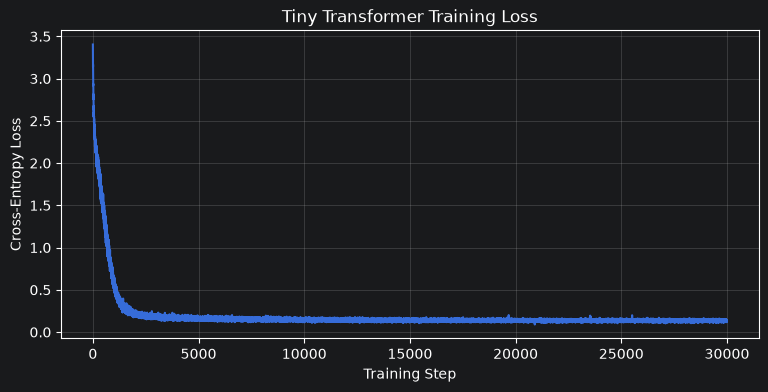

In [34]:
# ============================================================
# CELL 14F: VISUALIZE TRAINING LOSS
# ============================================================
# Purpose:
# Observe whether the model's prediction error decreases
# during training.
#
# A decreasing training loss suggests that the model is
# learning patterns in the training corpus.
#
# However, lower training loss does NOT guarantee that
# the model generalizes to unseen text.
# ============================================================

plt.figure(figsize=(9, 4))
plt.plot(loss_history)
plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("Tiny Transformer Training Loss")
plt.grid(alpha=0.3)
plt.show()

In [35]:
# ============================================================
# CELL 14G: EVALUATE THE TRAINED MODEL
# ============================================================
# IMPORTANT: Repeated training sentences also appear in validation.
# This validation score does not measure genuine generalization.
# Purpose:
# Training loss measures performance on training examples.
#
# Validation loss measures performance on held-out examples.
#
# Comparing them helps us detect possible overfitting.
#
# Our synthetic corpus repeats many sentences, so the
# validation set is not truly independent in content.
#
# For meaningful generalization evaluation, use a corpus
# with genuinely distinct training and validation examples.
# ============================================================

@torch.no_grad()
def evaluate(model, source, batches=20):
    """Estimate average loss over randomly sampled batches."""
    model.eval()
    losses = []

    for _ in range(batches):
        x, y = get_batch(source)
        losses.append(calculate_loss(model(x), y).item())

    model.train()
    return sum(losses) / len(losses)

train_loss = evaluate(model, train_data)
val_loss = evaluate(model, val_data)

print("Training loss:", round(train_loss, 4))
print("Validation loss:", round(val_loss, 4))

Training loss: 0.1353
Validation loss: 0.1321


# PART 8: GENERATE TEXT

In [36]:
# ============================================================
# CELL 14H: COMPARE TEXT BEFORE AND AFTER TRAINING
# ============================================================
# Purpose:
# Compare text from random weights with text from learned weights.
# The two outputs use the same prompt and sampling settings.
# ============================================================

AFTER_TRAINING = generate_text(model, "students ", max_new_tokens=60, temperature=0.7)
print("BEFORE TRAINING:", repr(BEFORE_TRAINING))
print("AFTER TRAINING: ", repr(AFTER_TRAINING))


BEFORE TRAINING: 'students wfhhipcctman\njl \nskfrocel.vmvlyelrmtwehgyl\nbnl.cehlbawhxks.t'
AFTER TRAINING:  'students develop artificial intelligence systems.\nlanguage models pre'


# Testing Variety in Text Generation using Temperature

In [37]:
# ============================================================
# CELL 15A: TEMPERATURE WITH FIVE POSSIBLE NEXT WORDS
# ============================================================
# Purpose:
# Demonstrate temperature using simple, fixed logits.
#
# Imagine the prompt:
# "Students love ..."
#
# The model assigns the following hypothetical scores.
#
# We change ONLY temperature.
# ============================================================

words = ["Python", "Django", "Coffee", "Exams", "Homework"]
logits_demo = torch.tensor([5.0, 4.0, 3.0, 2.0, 1.0])

temperatures = [0.1, 0.5, 1.0, 2.0, 5.0]

print(f"{'Temperature':<14}", end="")

for word in words:
    print(f"{word:<12}", end="")

print()

for temperature in temperatures:

    probs = F.softmax(logits_demo / temperature, dim=0)

    print(f"{temperature:<14.1f}", end="")

    for probability in probs:
        print(f"{probability.item():<12.3f}", end="")

    print()

Temperature   Python      Django      Coffee      Exams       Homework    
0.1           1.000       0.000       0.000       0.000       0.000       
0.5           0.865       0.117       0.016       0.002       0.000       
1.0           0.636       0.234       0.086       0.032       0.012       
2.0           0.429       0.260       0.158       0.096       0.058       
5.0           0.287       0.235       0.192       0.157       0.129       


In [38]:
# ============================================================
# CELL 15B: HOW TEMPERATURE CHANGES TOKEN PROBABILITIES
# ============================================================
# Purpose:
# Show how temperature changes the probability distribution
# over possible next tokens.
#
# Lower temperature:
#   Concentrates probability on the highest-scoring tokens.
#
# Higher temperature:
#   Distributes probability across more possible tokens.
#
# IMPORTANT:
# We use the SAME model, SAME prompt, and SAME logits.
# Only the temperature changes.
# ============================================================

prompt = "students "

model.eval()

with torch.no_grad():
    input_ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    temperature_logits = model(input_ids)[:, -1, :].squeeze()

temperatures = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]

print(f"{'Temperature':<15} {'Top Character':<18} {'Probability':<15} {'Entropy (bits)':<15}")
print("-" * 70)

for temperature in temperatures:
    probs = F.softmax(temperature_logits / temperature, dim=-1)

    top_id = torch.argmax(probs).item()
    top_prob = probs[top_id].item()
    entropy = -(probs * probs.clamp_min(1e-12).log2()).sum().item()

    print(f"{temperature:<15.2f} {repr(itos[top_id]):<18} {top_prob:<15.4f} {entropy:<15.4f}")

Temperature     Top Character      Probability     Entropy (bits) 
----------------------------------------------------------------------
0.01            'l'                0.9324          0.3569         
0.10            'l'                0.5625          1.0298         
0.50            'l'                0.3580          2.0966         
1.00            'l'                0.2694          2.4406         
2.00            'l'                0.2080          2.8502         
5.00            'l'                0.1249          3.9889         


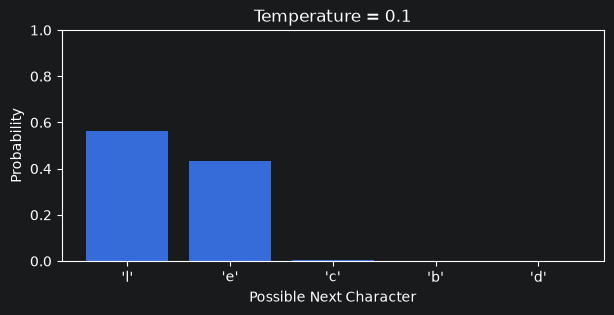

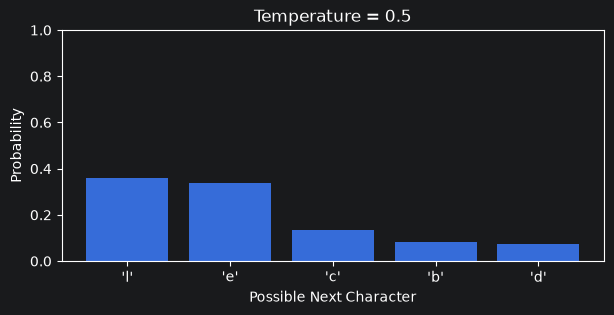

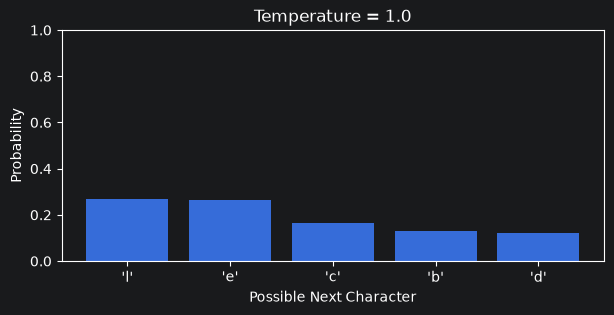

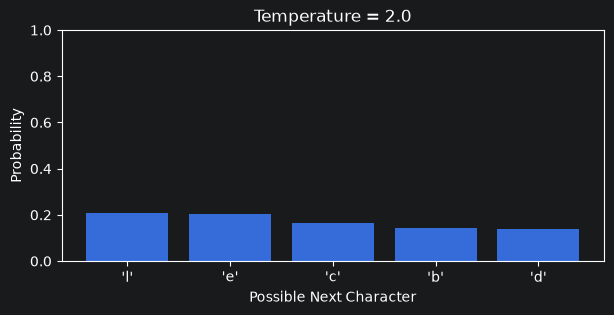

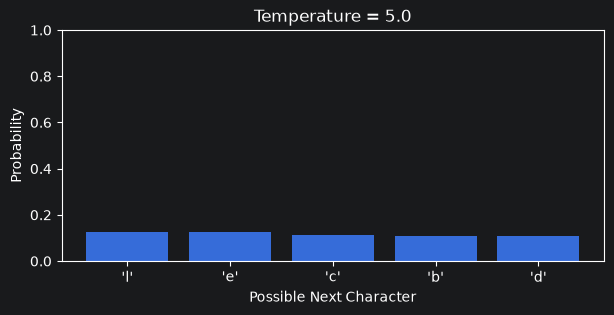

In [39]:
# ============================================================
# CELL 15C: VISUALIZE TEMPERATURE AND TOKEN PROBABILITIES
# ============================================================
# Purpose:
# Visualize how temperature redistributes probability
# across possible next characters.
#
# We select the five highest-scoring tokens at temperature 1.
# Then compare their probabilities at different temperatures.
#
# The model and logits remain unchanged.
# ============================================================



temperatures = [0.1, 0.5, 1.0, 2.0, 5.0]
top_ids = torch.topk(temperature_logits, k=5).indices

for temperature in temperatures:

    probs = F.softmax(temperature_logits / temperature, dim=-1)
    selected_probs = probs[top_ids].detach().cpu().numpy()
    labels = [repr(itos[i.item()]) for i in top_ids]

    plt.figure(figsize=(7, 3))
    plt.bar(labels, selected_probs)
    plt.title(f"Temperature = {temperature}")
    plt.xlabel("Possible Next Character")
    plt.ylabel("Probability")
    plt.ylim(0, 1)
    plt.show()

In [42]:
# ============================================================
# CELL 15D.1: OBSERVE GENERATION VARIETY
# ============================================================

# Step 1.3: Test generation temperatures
# Run using your selected trained model. Do not retrain between tests.

prompt = "students "
temperatures = [0.2, 0.5, 1.0, 2.0]
MAX_NEW_TOKENS = 300

model.eval()

temperature_results = []

for temperature in temperatures:
    response = generate_text(
        model,
        prompt,
        max_new_tokens=MAX_NEW_TOKENS,
        temperature=temperature
    )

    temperature_results.append({
        "Temperature": temperature,
        "Generated Text": response,
        "Observations": ""
    })

    print(f"\nTemperature: {temperature}")
    print(repr(response))

display(pd.DataFrame(temperature_results))


Temperature: 0.2
'students create innovative startup applications.\ndjango applications use models and views.\ntraining changes the weights of a neural network.\ninference uses previously learned parameters.\nthe university offers courses in informatics.\nstudents experiment with language models.\nartificial intelligence can genera'

Temperature: 0.5
'students experiment with language models.\nartificial intelligence can generate text.\nthe model predicts characters using probabilities.\nattention helps models use contextual information.\npython is useful for machine learning research.\nthe students are building useful software products.\nsmall language models '

Temperature: 1.0
'students create innovative startup applications.\ndjango applications use models and views.\ntraining changes the weights of a neural network.\ninference uses previously learned parameters.\nthe university offers courses in informattaics.\nstudents experiment with language models.\nartificial intelligence ca

,Temperature,Generated Text,Observations
0,0.2,students create innovative startup application...,
1,0.5,students experiment with language models.\nart...,
2,1.0,students create innovative startup application...,
3,2.0,students experiment with velop artificial inte...,


In [40]:
# ============================================================
# CELL 15D.2: OBSERVE GENERATION VARIETY
# ============================================================
# Purpose:
# Generate multiple responses at each temperature.
#
# Low temperature:
#   Repeated generations tend to be similar.
#
# High temperature:
#   Repeated generations tend to be more diverse.
#
# We keep the model, prompt, and output length constant.
# ============================================================

prompt = "students "

temperatures = [0.01, 0.1, 0.5, 1.0, 2.0]

for temperature in temperatures:

    print("\n" + "=" * 65)
    print(f"TEMPERATURE: {temperature}")
    print("=" * 65)

    for run in range(3):
        response = generate_text(
            model,
            prompt,
            max_new_tokens=30,
            temperature=temperature)

        print(f"Run {run + 1}: {response!r}")


TEMPERATURE: 0.01
Run 1: 'students learn python programming.\nstud'
Run 2: 'students learn python programming.\nstud'
Run 3: 'students learn python programming.\nstud'

TEMPERATURE: 0.1
Run 1: 'students experiment with language model'
Run 2: 'students learn python programming.\nstud'
Run 3: 'students learn python programming.\nstud'

TEMPERATURE: 0.5
Run 1: 'students experiment with language model'
Run 2: 'students experiment with language model'
Run 3: 'students experiment with language model'

TEMPERATURE: 1.0
Run 1: 'students develop artificial intelligenc'
Run 2: 'students create innovative startup appl'
Run 3: 'students learn python programming.\nstud'

TEMPERATURE: 2.0
Run 1: 'students are buildits.\ndjango applicati'
Run 2: 'students velop artificial intelligence '
Run 3: 'students oken.\nork.\ninference uses prev'


# PART 9: SAVE AND RELOAD OUR MODEL

# ESTIMATED TRAINING TIME & TRAINING CAPACITY BASED ON CURRENT COMPUTER

In [ ]:
# ============================================================
# CELL 16A: ESTIMATE MAXIMUM TRAINABLE LANGUAGE MODEL SIZE
# ============================================================
# Purpose:
# 1. Detect the computer's CPU, RAM, and GPU availability.
# 2. Estimate training capacity based on TOTAL installed RAM.
# 3. Calculate the approximate maximum trainable parameters.
# 4. Compare model sizes ranging from 10K to 70B parameters.
#
# Assumptions:
# - Full-parameter training using FP32 and AdamW.
# - Approximately 16 bytes per parameter:
#       Weights:         4 bytes
#       Gradients:       4 bytes
#       AdamW State 1:   4 bytes
#       AdamW State 2:   4 bytes
#
# - Use 50% of total RAM as a simplified training budget.
# - Reserve the remaining 50% for the operating system,
#   activations, temporary tensors, and other processes.
#
# IMPORTANT:
# This is a theoretical memory-based estimate.
# It does NOT guarantee successful or reasonably fast training.
# ============================================================

# -----------------------------
# CONFIGURATION
# -----------------------------

BYTES_PER_PARAMETER = 16
RAM_USAGE_FACTOR = 0.50

# -----------------------------
# DETECT COMPUTER HARDWARE
# -----------------------------

system = platform.system()
processor = platform.processor() or platform.machine()

ram = psutil.virtual_memory()

total_ram_gb = ram.total / 1e9
available_ram_gb = ram.available / 1e9

if torch.cuda.is_available():
    device = "CUDA"
    gpu_name = torch.cuda.get_device_name(0)
    total_gpu_memory = torch.cuda.get_device_properties(0).total_memory

    # CUDA training generally uses dedicated GPU memory.
    total_memory = total_gpu_memory
    memory_type = "GPU VRAM"

elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "Apple MPS"
    gpu_name = "Apple Silicon GPU"

    # Apple Silicon uses unified system memory.
    total_memory = ram.total
    memory_type = "Unified RAM"

else:
    device = "CPU"
    gpu_name = "Not detected"

    total_memory = ram.total
    memory_type = "System RAM"

# -----------------------------
# ESTIMATE TRAINING CAPACITY
# -----------------------------

training_memory = total_memory * RAM_USAGE_FACTOR
max_parameters = int(training_memory / BYTES_PER_PARAMETER)

# -----------------------------
# DISPLAY HARDWARE INFORMATION
# -----------------------------

print("=" * 90)
print("COMPUTER HARDWARE")
print("=" * 90)

print("Operating System:", system)
print("Processor:", processor)
print("Physical CPU Cores:", psutil.cpu_count(logical=False))
print("Logical CPU Cores:", psutil.cpu_count(logical=True))
print(f"Total Installed RAM: {total_ram_gb:.2f} GB")
print(f"Currently Available RAM: {available_ram_gb:.2f} GB")
print("Acceleration:", device)
print("GPU:", gpu_name)
print("Memory Type Used for Estimate:", memory_type)
print(f"Total Memory Used for Estimate: {total_memory / 1e9:.2f} GB")

# -----------------------------
# DISPLAY ESTIMATED CAPACITY
# -----------------------------

print("\n" + "=" * 90)
print("ESTIMATED TRAINING CAPACITY (BASED ON TOTAL MEMORY)")
print("=" * 90)

print(f"Total {memory_type}: {total_memory / 1e9:.2f} GB")
print(f"Memory allocated for training estimate: {training_memory / 1e9:.2f} GB")
print(f"RAM usage factor: {RAM_USAGE_FACTOR:.0%}")
print(f"Estimated memory per parameter: {BYTES_PER_PARAMETER} bytes")

print(f"\nEstimated maximum parameters: {max_parameters:,}")
print(f"Approximately: {max_parameters / 1e6:.2f} million parameters")

# -----------------------------
# COMPARE DIFFERENT MODEL SIZES
# -----------------------------

model_sizes = {
    "10K": 10_000,
    "25K": 25_000,
    "50K": 50_000,
    "100K": 100_000,
    "250K": 250_000,
    "500K": 500_000,

    "1M": 1_000_000,
    "2M": 2_000_000,
    "5M": 5_000_000,
    "10M": 10_000_000,
    "25M": 25_000_000,
    "50M": 50_000_000,
    "100M": 100_000_000,
    "250M": 250_000_000,
    "500M": 500_000_000,

    "1B": 1_000_000_000,
    "1.5B": 1_500_000_000,
    "2B": 2_000_000_000,
    "3B": 3_000_000_000,
    "4B": 4_000_000_000,
    "7B": 7_000_000_000,
    "8B": 8_000_000_000,
    "10B": 10_000_000_000,
    "13B": 13_000_000_000,
    "20B": 20_000_000_000,
    "30B": 30_000_000_000,
    "70B": 70_000_000_000
}

# -----------------------------
# DISPLAY MODEL COMPARISON
# -----------------------------

print("\n" + "=" * 90)
print("CAN YOUR COMPUTER TRAIN THESE MODEL SIZES?")
print("=" * 90)

print(f"{'Model Size':<12} {'Parameters':>18} {'Est. RAM Needed':>20} {'Memory Check':>20}")
print("-" * 90)

for name, parameters in model_sizes.items():

    required_memory = parameters * BYTES_PER_PARAMETER
    required_gb = required_memory / 1e9

    status = "Within budget" if required_memory <= training_memory else "Exceeds budget"

    print(f"{name:<12} {parameters:>18,} {required_gb:>17.4f} GB {status:>20}")

print("\n" + "=" * 90)
print("IMPORTANT NOTES")
print("=" * 90)

print("1. Estimates are based on TOTAL installed memory, not currently available RAM.")
print("2. CUDA estimates use total dedicated GPU VRAM rather than system RAM.")
print("3. Apple Silicon estimates use total unified system memory.")
print("4. RAM estimates include weights, gradients, and AdamW optimizer states.")
print("5. Additional memory is needed for activations, batches, and temporary tensors.")
print("6. 'Within budget' does NOT guarantee successful training.")
print("7. Training speed depends on hardware, architecture, and dataset size.")
print("8. Estimates assume full-parameter FP32 training, not LoRA or quantization.")

In [ ]:
# ============================================================
# CELL 16B: ESTIMATE LANGUAGE MODEL TRAINING TIME
# ============================================================
# Purpose:
# 1. Estimate training tokens from dataset size.
# 2. Estimate training FLOPs for different model sizes.
# 3. Estimate training time for multiple epochs.
# 4. Compare training time across models from Cell 16C.
# 5. Identify models exceeding the estimated memory budget.
#
# Assumptions:
# - Training a dense Transformer language model from scratch.
# - Full-parameter training using FP32 and AdamW.
# - Approximately 6 FLOPs per parameter per training token.
# - Dataset size is converted to tokens using an assumed
#   average number of bytes per token.
# - Effective training throughput is configurable.
#
# IMPORTANT:
# This is a theoretical compute-based estimate.
# Actual training time depends on model architecture,
# hardware utilization, sequence length, batch size,
# data loading, and training implementation.
# ============================================================


# -----------------------------
# CONFIGURATION
# -----------------------------

DATASET_SIZE_GB = 7.0
BYTES_PER_TOKEN = 4.0
FLOPS_PER_PARAMETER_TOKEN = 6

EPOCHS_TO_COMPARE = [1, 3, 5]

# Assumed sustained training throughput.
# Replace with measured throughput when available.
EFFECTIVE_TFLOPS = 1.0

# -----------------------------
# VALIDATE CONFIGURATION
# -----------------------------

if DATASET_SIZE_GB <= 0:
    raise ValueError("DATASET_SIZE_GB must be positive.")

if BYTES_PER_TOKEN <= 0:
    raise ValueError("BYTES_PER_TOKEN must be positive.")

if EFFECTIVE_TFLOPS <= 0:
    raise ValueError("EFFECTIVE_TFLOPS must be positive.")

if not EPOCHS_TO_COMPARE or any(e <= 0 for e in EPOCHS_TO_COMPARE):
    raise ValueError("EPOCHS_TO_COMPARE must contain positive values.")

# -----------------------------
# ESTIMATE DATASET TOKENS
# -----------------------------

dataset_bytes = DATASET_SIZE_GB * 1e9
estimated_tokens = dataset_bytes / BYTES_PER_TOKEN

# -----------------------------
# ESTIMATE COMPUTE THROUGHPUT
# -----------------------------

effective_flops_per_second = EFFECTIVE_TFLOPS * 1e12

# -----------------------------
# DISPLAY DATASET INFORMATION
# -----------------------------

print("=" * 110)
print("LANGUAGE MODEL TRAINING TIME ESTIMATION")
print("=" * 110)

print(f"Dataset size: {DATASET_SIZE_GB:.2f} GB")
print(f"Assumed bytes per token: {BYTES_PER_TOKEN:.2f}")
print(f"Estimated training tokens: {estimated_tokens:,.0f}")
print(f"Estimated tokens (billions): {estimated_tokens / 1e9:.3f} B")

print(f"\nAcceleration: {device}")
print(f"GPU: {gpu_name}")
print(f"Total installed memory: {total_memory / 1e9:.2f} GB")
print(f"Estimated training memory budget: {training_memory / 1e9:.2f} GB")

print(f"\nAssumed effective throughput: {EFFECTIVE_TFLOPS:.3f} TFLOP/s")
print(f"Training FLOPs per parameter per token: {FLOPS_PER_PARAMETER_TOKEN}")

# -----------------------------
# FORMAT TRAINING DURATION
# -----------------------------

def format_training_time(seconds):

    if seconds < 60:
        return f"{seconds:.1f} sec"

    if seconds < 3600:
        return f"{seconds / 60:.1f} min"

    if seconds < 86400:
        return f"{seconds / 3600:.1f} hr"

    return f"{seconds / 86400:.1f} days"

# -----------------------------
# ESTIMATE TRAINING TIMES
# -----------------------------

training_time_results = {}

for name, parameters in model_sizes.items():

    required_memory = parameters * BYTES_PER_PARAMETER
    memory_fits = required_memory <= training_memory

    flops_per_epoch = (
        FLOPS_PER_PARAMETER_TOKEN
        * parameters
        * estimated_tokens
    )

    seconds_per_epoch = (
        flops_per_epoch / effective_flops_per_second
    )

    epoch_times = {
        epochs: seconds_per_epoch * epochs
        for epochs in EPOCHS_TO_COMPARE
    }

    training_time_results[name] = {
        "parameters": parameters,
        "required_memory_gb": required_memory / 1e9,
        "memory_fits": memory_fits,
        "flops_per_epoch": flops_per_epoch,
        "seconds_per_epoch": seconds_per_epoch,
        "epoch_times": epoch_times
    }

# -----------------------------
# DISPLAY TRAINING TIME TABLE
# -----------------------------

print("\n" + "=" * 110)
print("ESTIMATED TRAINING TIME BY MODEL SIZE")
print("=" * 110)

header = f"{'Model':<10} {'Parameters':>16} {'Memory':>12}"

for epochs in EPOCHS_TO_COMPARE:
    header += f" {str(epochs) + ' Epoch(s)':>16}"

header += f" {'Memory Check':>16}"

print(header)
print("-" * 110)

for name, result in training_time_results.items():

    row = (
        f"{name:<10} "
        f"{result['parameters']:>16,} "
        f"{result['required_memory_gb']:>9.2f} GB"
    )

    for epochs in EPOCHS_TO_COMPARE:
        seconds = result["epoch_times"][epochs]
        row += f" {format_training_time(seconds):>16}"

    status = "Within budget" if result["memory_fits"] else "Exceeds budget"
    row += f" {status:>16}"

    print(row)

# -----------------------------
# IDENTIFY LARGEST MODEL
# -----------------------------

trainable_models = {
    name: result
    for name, result in training_time_results.items()
    if result["memory_fits"]
}

print("\n" + "=" * 110)
print("MAXIMUM THEORETICALLY TRAINABLE MODEL")
print("=" * 110)

if trainable_models:

    largest_name = max(
        trainable_models,
        key=lambda name: trainable_models[name]["parameters"]
    )

    largest = trainable_models[largest_name]

    print(f"Model size: {largest_name}")
    print(f"Parameters: {largest['parameters']:,}")
    print(f"Estimated memory: {largest['required_memory_gb']:.2f} GB")

    for epochs in EPOCHS_TO_COMPARE:
        seconds = largest["epoch_times"][epochs]
        print(f"Estimated time ({epochs} epochs): {format_training_time(seconds)}")

else:
    print("No model sizes fit within the estimated training memory budget.")

# -----------------------------
# IMPORTANT NOTES
# -----------------------------

print("\n" + "=" * 110)
print("IMPORTANT NOTES")
print("=" * 110)

print("1. Training times assume the dataset consists entirely of usable training text.")
print("2. Token counts are estimated from dataset bytes, not measured using a tokenizer.")
print("3. Training FLOPs use the approximate 6 × parameters × tokens formula.")
print("4. Throughput is assumed rather than measured on this computer.")
print("5. Actual training time may differ substantially from these estimates.")
print("6. Memory checks use the theoretical budget from Cell 16C.")
print("7. Memory feasibility does not guarantee successful training.")
print("8. Times exclude tokenization, preprocessing, validation, and checkpointing.")
print("9. Training times assume each epoch processes the entire dataset once.")
print("10. For accurate estimates, benchmark actual training steps on the target hardware.")

# What Did We Build?

We created a real **decoder-only Transformer language model from scratch**.

Unlike our earlier Hugging Face experiments, we did not download pretrained model weights.

Instead, we:

1. Created our own character-level tokenizer.
2. Converted text into numerical token IDs.
3. Created token and positional embeddings.
4. Implemented causal multi-head self-attention.
5. Constructed Transformer blocks.
6. Calculated trainable parameters.
7. Inspected logits and probabilities.
8. Calculated cross-entropy loss.
9. Used backpropagation to calculate gradients.
10. Used AdamW to update model parameters.
11. Trained the model using a text corpus.
12. Generated new text using the trained model.
13. Experimented with sampling temperature.
14. Saved and reloaded our learned parameters.

## The Big Picture

**Training from Scratch**

`Training Data → Randomly Initialized Model → Loss → Backpropagation → Optimizer → Learned Weights`

**Inference**

`Prompt → Tokenizer → Trained Model → Logits → Probabilities → Generated Tokens → Text`

## Important Distinction

| Concept | What Happens? | Do Model Weights Change? |
|---|---|---|
| **Training from Scratch** | Learn parameters from an initial untrained state | Yes |
| **Fine-Tuning** | Continue training an existing pretrained model | Yes, at least some parameters |
| **Prompt Engineering** | Change the instructions/input | No |
| **RAG** | Retrieve and provide external information during inference | No change to the generator's weights |
| **Inference** | Use learned parameters to generate predictions | No |

## Reflection Questions

1. Why did the model initially generate meaningless text?
2. What does a parameter represent?
3. How did increasing the embedding dimension affect parameter count?
4. Why does a Transformer need positional information?
5. What is the difference between logits and probabilities?
6. What does temperature change?
7. What does cross-entropy loss measure?
8. What does backpropagation calculate?
9. What does AdamW actually do?
10. Why is our tiny Transformer much less capable than a pretrained Hugging Face LLM?

> **Key Takeaway:** A language model is not simply a collection of rules. It is a parameterized mathematical system whose parameters are learned through training and then used to predict tokens during inference.

# PART 10: STUDENT EXPERIMENTS

In [ ]:
# ============================================================
# CELL 17: ASSIGNMENT 7 (PART-2) — CHANGE THE ARCHITECTURE
# ============================================================
# Purpose:
# Investigate how architectural choices affect parameter count.
#
# IMPORTANT:
# These models are newly initialized.
# They are NOT trained in this experiment.
#
# Change:
#   - Embedding dimension
#   - Number of attention heads
#   - Number of Transformer blocks
#   - Feed-forward dimension
#
# Observe:
#   - Total trainable parameters
#   - Whether changing attention heads changes parameter count
#   - How increasing layers changes model size
# ============================================================

experiments = [
    {"embedding_dim": 24, "num_heads": 2, "num_layers": 1, "feedforward_dim": 96},
    {"embedding_dim": 48, "num_heads": 2, "num_layers": 1, "feedforward_dim": 192},
    {"embedding_dim": 48, "num_heads": 4, "num_layers": 1, "feedforward_dim": 192},
    {"embedding_dim": 48, "num_heads": 2, "num_layers": 2, "feedforward_dim": 192},
    {"embedding_dim": 96, "num_heads": 4, "num_layers": 2, "feedforward_dim": 384}
]

for config in experiments:

    test_model = TinyTransformerLM(
        vocab_size=VOCAB_SIZE,
        context_length=CONTEXT_LENGTH,
        **config
    )

    parameters = sum(p.numel() for p in test_model.parameters())

    print(config)
    print(f"Parameters: {parameters:,}\n")